# Analysis of SAR Data #

This notebook is meant to catalogue some basic methods of SAR data analysis. As a use case, this notebook and the accompanying functions will focus on vessel detection using both scientific multi-channel SAR raster data and pixelized SAR images. 

The purpose of this notebook is to serve as a personal record of SAR image processing, but I plan to publish it on Github as a public journal. 

### Multichannel Raster Data ### 

This first cell walks through some basic data ingestion for scientific SAR data. This cell pulls data from Sentinel-1 through Planetary Computer's STAC API, it then performs basic analysis on the channels that are available and what they look like. 

Total Tiles Collected 10

Each Tile Contains the following Assets:
vh
vv
tilejson
rendered_preview
This scene is centered on 36.1235, -4.1607

The closest city to this tile is Fuengirola, ES which is 61.82 km from scene center


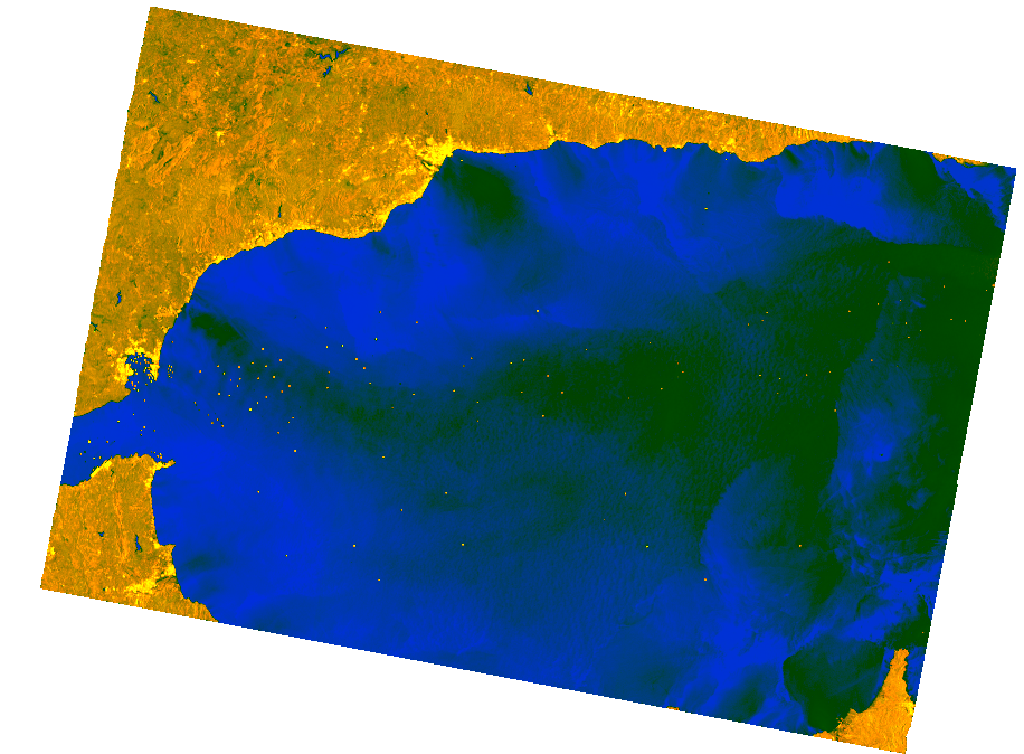

The Following images display a comparision between VH and VV polarization of the same tile.


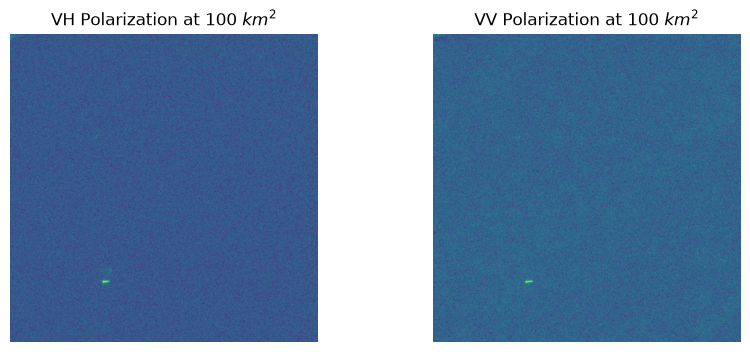

In [1]:
# Logical Dependencies
import pystac_client

# Local Dependencies
from config import PLANETARY_COMPUTER_SENTINEL1
from sar_multichannel_analysis import multichannel_data_analysis


# Setup Planetary Computer connection
catalog = pystac_client.Client.open(PLANETARY_COMPUTER_SENTINEL1)

search = catalog.search(
    collections=["sentinel-1-rtc"],
    bbox=[-5.8, 35.7, -5.1, 36.3],
    datetime="2025-01-01/2025-12-31",
    max_items=10,
)

# Item Analysis
items = list(search.items())
multichannel_data_analysis(items)

### SSDD Dataset Analysis ### 

This section walks through the basic composition and analysis of the SSDD dataset. This Dataset is prepartitioned by huggingface into train, test, validate sets. 

It is worth noting that this dataset contains static SAR images rather than raw polarized data. As a result this data has already been abstracted in post-processing. More detailed analysis may be performed with the polarized data, but I do not currently have labels for a dataset like that. 

This first cell creates a data loader object to help streamline the data handling. It then shows a tree of the data within.

In [2]:
# To download the data, uncommend the following two lines and run this cell
#from helpers.download_ssdd import download_ssdd
#download_ssdd()

# Dependencies
from helpers.data_loader import DataLoader

# If you are pulling the SSDD data from elsewhere, edit the line below
from config import BASE_PATH
SSDD_PATH = BASE_PATH

# Setup Dataloader
dl = DataLoader(SSDD_PATH)



New Data Loader Tree: 

├── images
│   ├── test
│   │   ├── ... .jpg
│   │   └── ... .jsonl
│   ├── train
│   │   ├── ... .jpg
│   │   └── ... .jsonl
│   └── valid
│       ├── ... .jpg
│       └── ... .jsonl
├── labels
│   ├── test
│   │   └── ... .txt
│   ├── train
│   │   └── ... .txt
│   ├── valid
│   │   └── ... .txt
│   └── ... .cache
├── ... .yaml
└── ... [no extension]


The Complete Inventory of this DataLoader: 

       images  ships  min_width  max_width  min_height  max_height
split                                                             
test      232    546        300        668         192         494
train     789   1756        214        653         190         526
valid     139    285        286        589         218         483


A sample of the data pairings can be extracted and displayed with the cell below.

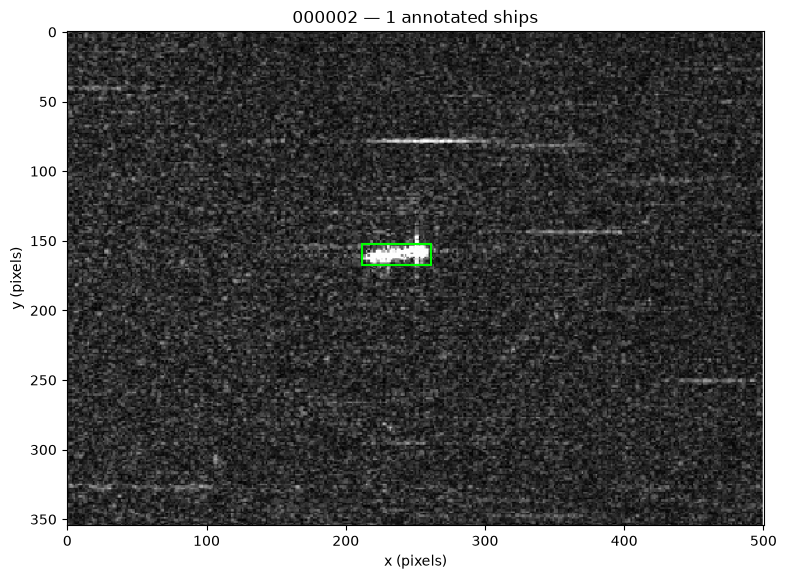

(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': '000002 — 1 annotated ships'}, xlabel='x (pixels)', ylabel='y (pixels)'>)

In [3]:
# Get all the image paths for training images
train_files = dl.get_images()

# Consider and display the content for the combined sample of one of these images
sample = dl.load_sample(train_files[0])
sample.show()

## Ship Identification ##

As a data processing use case, the next section of this notebook will attempt to use the labelled SSDD data to predict the location of ships in an ocean scene. Both Determinitsic and Deep Learning approaches will be used and then compaired. 


### Deterministic Prediction ### 

The first method of prediciton will be to use the scene's brightness contrast to identify areas of high energy return. This approach assumes that in an oceanic scene, all areas of high contrast (with a minimum pixel size filter) will represent a ship. This is a fairly safe assumption for this level of analysis, but it is worth noting that there may be cases of false positives. 

The first attempt at this will be simple and will include:
1. Establish an average energy for the scene by determining the average gray value
1. Call out all pixels in the scene with brightness values above one standard deviation of this average
1. Consider all collections of more than a base number of pixels (e.g. 5 pixels)

Sample Stats:
   - Mean: 44.9943774422985
   - Standard Dev: 28.049535131891066
   - Threshold: 101.09344770608064



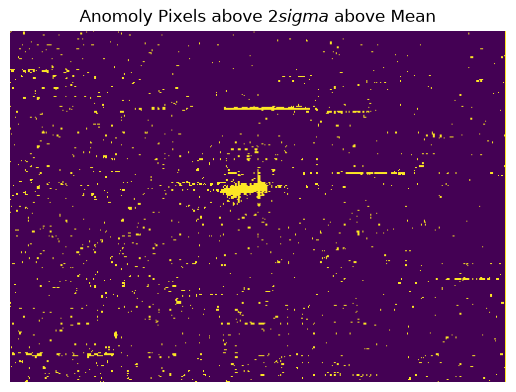

1 Total Boxes Identified
Evaluation Results:
   - id: 000002
   - path: SSDD_data/data/images/train/000002.jpg
   - true_positives: 1
   - false_positives: 0
   - false_negatives: 0
   - precision: 1.0
   - recall: 1.0
   - f1: 1.0
   - matches: [{'prediction_index': 0, 'label_index': 0, 'iou': 0.4186455309542667}]
   - false_positive_indices: []
   - false_negative_indices: []
   - iou_matrix: [[0.41864553]]


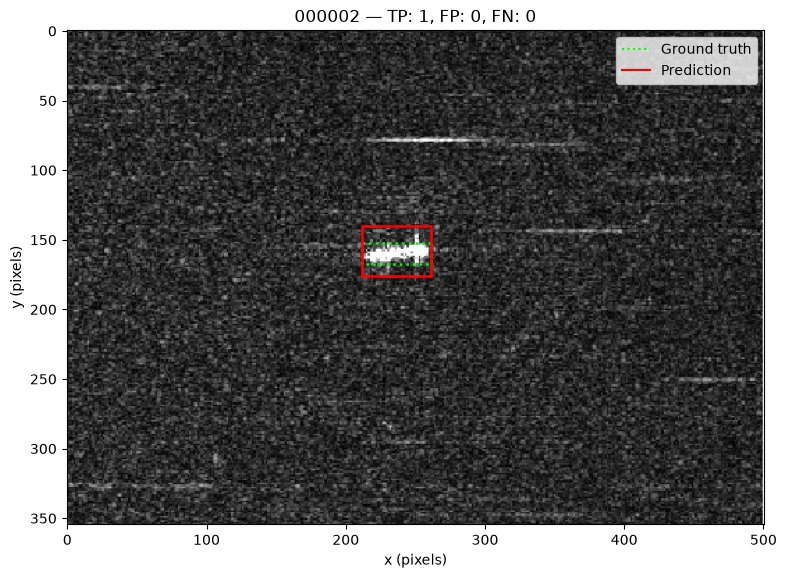

In [4]:
# Load the deterministic model
from deterministic_model import mean_threshold_model

# Execute the sample
sample = dl.load_sample(dl.get_images()[0])
pred = mean_threshold_model(sample, show_checkpoints=True)

# Evaluate the prediction
results = sample.evaluate(pred, iou_threshold=0.3, plot=True)

With one sample complete, it is useful to test the deterministic model on the validation set to determine overall performance.

In [5]:
import pandas as pd
import numpy as np

dl.mode = 'valid'
img_list = dl.get_images()

records = []

# Iterate through all the images, evaluate and record performance
for img in img_list:
    # Evaluate
    sample = dl.load_sample(img)
    pred = mean_threshold_model(sample)
    results = sample.evaluate(pred, iou_threshold=0.3)

    # Record results
    new_row = results.copy()
    del(new_row['matches'])
    del(new_row['iou_matrix'])
    del(new_row['false_positive_indices'])
    del(new_row['false_negative_indices'])

    records.append(new_row)  


# Generate Composite Results
all_results = pd.DataFrame(records)
vdf = dl.inventory[dl.inventory['split']=='valid']
total_ships = vdf['n_ships'].sum()
det_results = {
    'True_Positives_Detected': np.sum(all_results.true_positives),
    'True_Positive_Percentage': np.sum(all_results.true_positives)/total_ships,
    'False_Positive_Detection': np.sum(all_results.false_positives)/total_ships,
    'False_Negative_Detection': np.sum(all_results.false_negatives)/total_ships,
    'Average_Precision': np.average(all_results.precision),
    'Average_Recall': np.average(all_results.recall),
    'Average_F1': np.average(all_results.f1)
}

print('Results summary over Validation Set: \n')
for key, value in det_results.items(): print(f'   - {key}: {value}')


Results summary over Validation Set: 

   - True_Positives_Detected: 217
   - True_Positive_Percentage: 0.7614035087719299
   - False_Positive_Detection: 2.1157894736842104
   - False_Negative_Detection: 0.23859649122807017
   - Average_Precision: 0.5861167732836751
   - Average_Recall: 0.8263189448441246
   - Average_F1: 0.6179556908131604


Evaluation Results:
   - id: 000022
   - path: SSDD_data/data/images/valid/000022.jpg
   - true_positives: 0
   - false_positives: 9
   - false_negatives: 1
   - precision: 0.0
   - recall: 0.0
   - f1: 0.0
   - matches: []
   - false_positive_indices: [0, 1, 2, 3, 4, 5, 6, 7, 8]
   - false_negative_indices: [0]
   - iou_matrix: [[0.19781006]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]


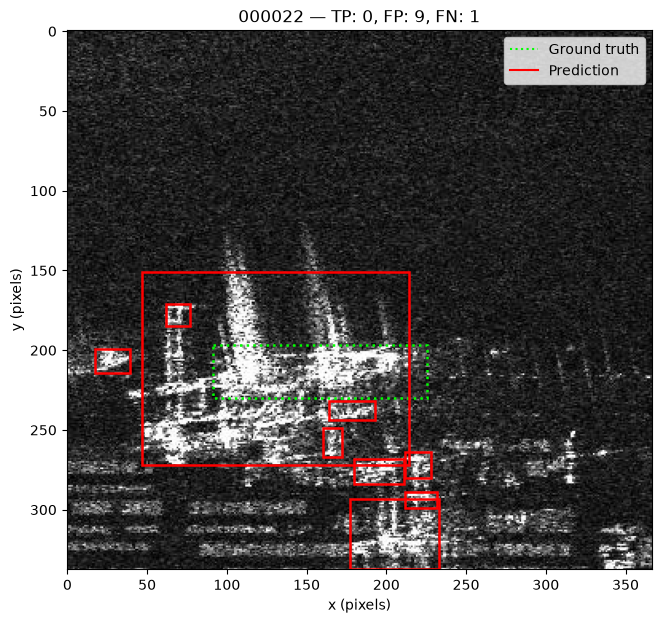

Evaluation Results:
   - id: 000216
   - path: SSDD_data/data/images/valid/000216.jpg
   - true_positives: 0
   - false_positives: 6
   - false_negatives: 2
   - precision: 0.0
   - recall: 0.0
   - f1: 0.0
   - matches: []
   - false_positive_indices: [0, 1, 2, 3, 4, 5]
   - false_negative_indices: [0, 1]
   - iou_matrix: [[0.25981847 0.        ]
 [0.         0.        ]
 [0.         0.        ]
 [0.         0.        ]
 [0.         0.        ]
 [0.         0.        ]]


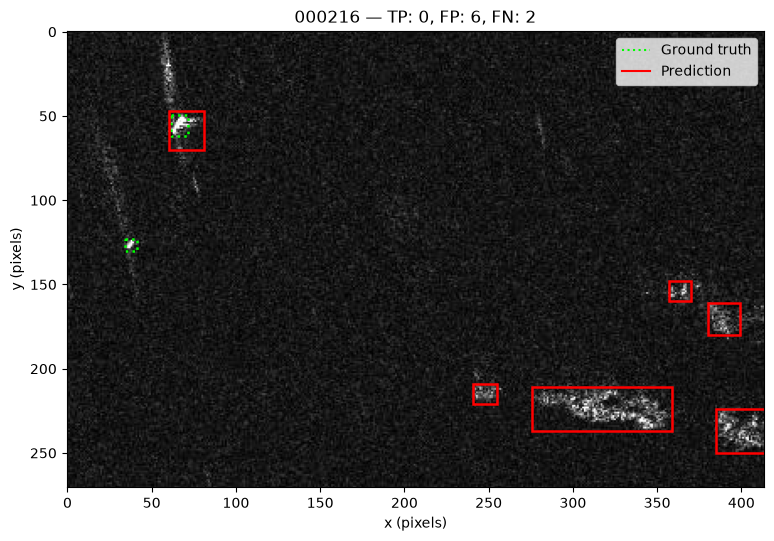

Evaluation Results:
   - id: 000252
   - path: SSDD_data/data/images/valid/000252.jpg
   - true_positives: 0
   - false_positives: 22
   - false_negatives: 1
   - precision: 0.0
   - recall: 0.0
   - f1: 0.0
   - matches: []
   - false_positive_indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
   - false_negative_indices: [0]
   - iou_matrix: [[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.24678396]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]


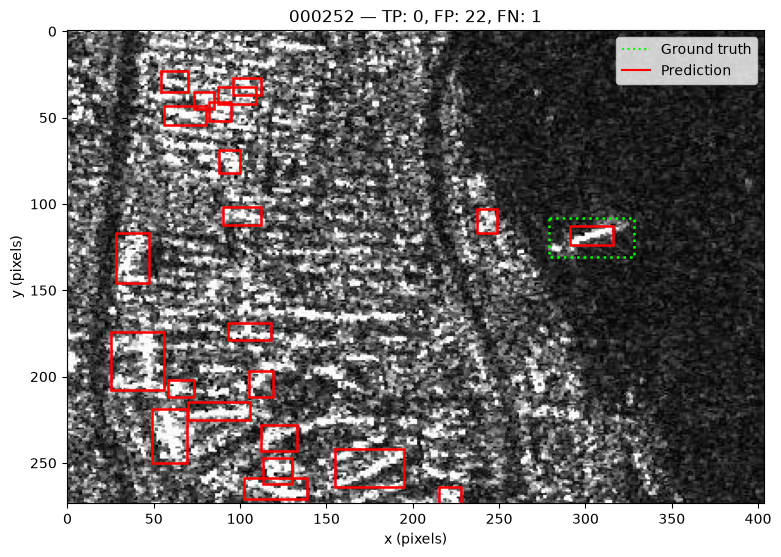

Evaluation Results:
   - id: 000602
   - path: SSDD_data/data/images/valid/000602.jpg
   - true_positives: 0
   - false_positives: 1
   - false_negatives: 1
   - precision: 0.0
   - recall: 0.0
   - f1: 0.0
   - matches: []
   - false_positive_indices: [0]
   - false_negative_indices: [0]
   - iou_matrix: [[0.29254938]]


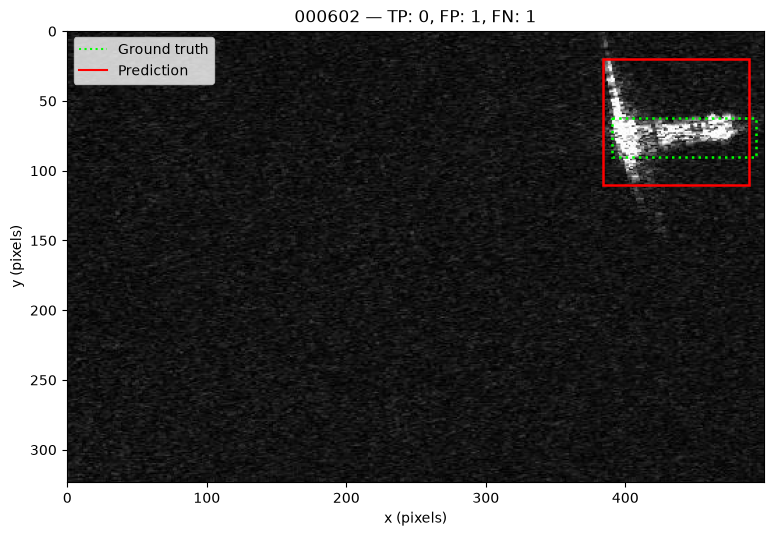

Evaluation Results:
   - id: 000632
   - path: SSDD_data/data/images/valid/000632.jpg
   - true_positives: 0
   - false_positives: 1
   - false_negatives: 1
   - precision: 0.0
   - recall: 0.0
   - f1: 0.0
   - matches: []
   - false_positive_indices: [0]
   - false_negative_indices: [0]
   - iou_matrix: [[0.16934656]]


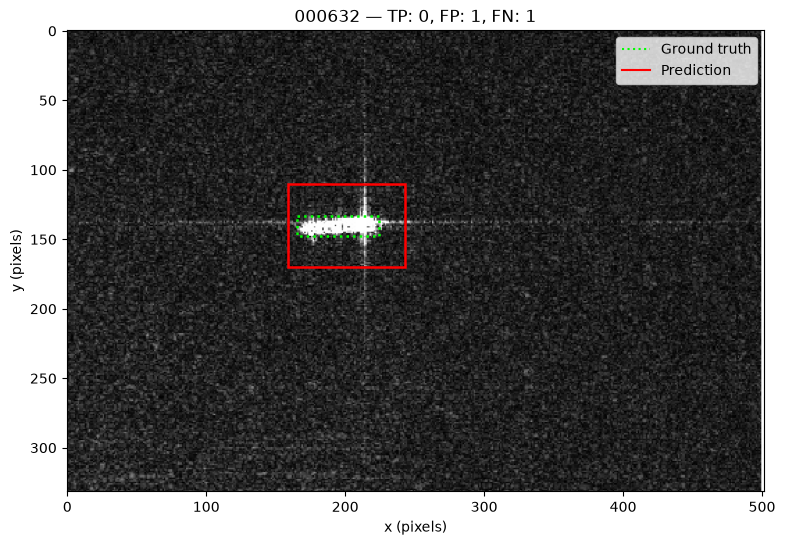

Evaluation Results:
   - id: 000766
   - path: SSDD_data/data/images/valid/000766.jpg
   - true_positives: 0
   - false_positives: 4
   - false_negatives: 1
   - precision: 0.0
   - recall: 0.0
   - f1: 0.0
   - matches: []
   - false_positive_indices: [0, 1, 2, 3]
   - false_negative_indices: [0]
   - iou_matrix: [[0.        ]
 [0.        ]
 [0.        ]
 [0.14560268]]


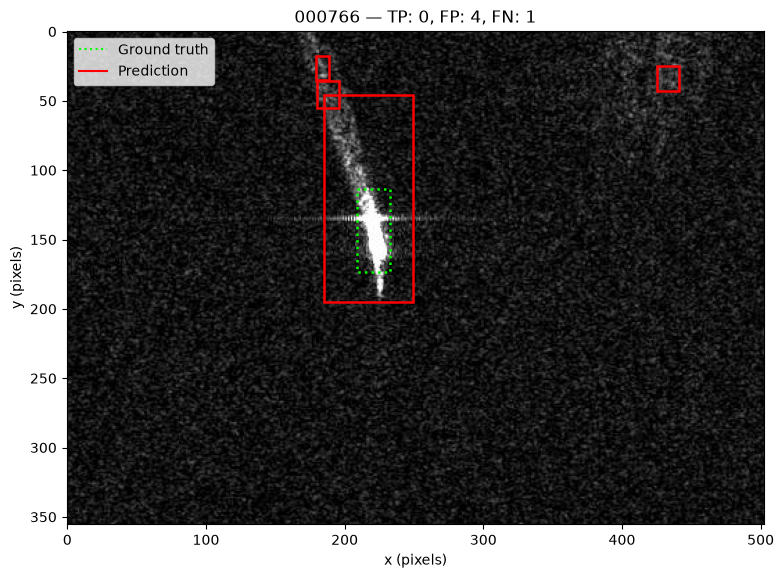

Evaluation Results:
   - id: 000773
   - path: SSDD_data/data/images/valid/000773.jpg
   - true_positives: 0
   - false_positives: 3
   - false_negatives: 1
   - precision: 0.0
   - recall: 0.0
   - f1: 0.0
   - matches: []
   - false_positive_indices: [0, 1, 2]
   - false_negative_indices: [0]
   - iou_matrix: [[0.        ]
 [0.        ]
 [0.18329791]]


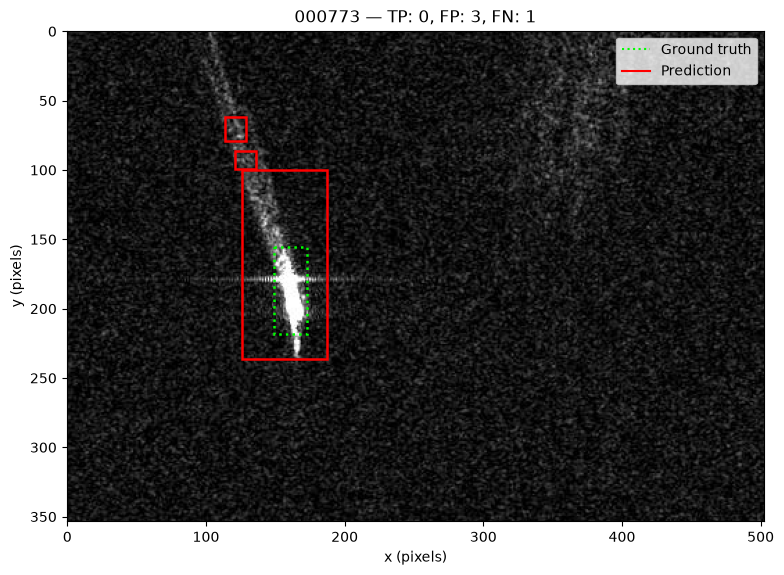

In [6]:
incorrect = all_results[all_results['recall']<0.5]
limit = 7
i = 0
for img in incorrect['path']:
    i+=1
    if i > limit: break
    sample = dl.load_sample(img)
    pred = mean_threshold_model(sample)
    sample.evaluate(pred,iou_threshold=0.3, plot=True)

**Analysis:**

Note that in these reviews that in many cases, the images that were inaccurate fell under two cases:
1. Shore Images (False Negatives) - Images that were taken while the ship was close to port resulted in poor accuracy because the shoreline raised the mean pixel value of the scene such that ships were not evenly distinguished
1. Wakes (False Positives) - In many cases, the wake trailing the ships created areas of high reflectivity, this is likely becuase Bragg resonance was achieved as the ship altered the water's wave pattern

## Deep Learning with YOLO ##  

Now we I will perform a similar analysis on the images using the training and testing sets to fine-tune a small YOLO model. The model will then be used to evaluate the validation images and results will be compared against the deterministic model.

Base model selected: YOLO1 nano *(yolo11n.pt)*

This training will be conducted using Mac MPS

In [7]:
#%pip install ultralytics pyyaml
import yaml
import torch
import ultralytics
from pathlib import Path
from config import BASE_PATH

# Set the Device

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("Apple GPU available:", torch.backends.mps.is_available())
print("CUDA GPU available:", torch.cuda.is_available())

if torch.cuda.is_available(): device = 0 # NVIDIA GPU
elif torch.backends.mps.is_available(): device = "mps" # Your M1 GPU
else: device = "cpu"

print("Training device:", device, '\n')

# Setup the Config

DATA_ROOT = Path(BASE_PATH).resolve()
CONFIG_PATH = Path("ssdd.yaml").resolve()

config = {
    "path": str(DATA_ROOT),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "names": {0: "ship"},
}

CONFIG_PATH.write_text(yaml.safe_dump(config, sort_keys=False))
print('Config:')
print(CONFIG_PATH.read_text())

Ultralytics: 8.4.184
PyTorch: 2.14.1
Apple GPU available: True
CUDA GPU available: False
Training device: mps 

Config:
path: /Users/willrmckinnon/VS_Code/SARSandbox/SSDD_data/data
train: images/train
val: images/valid
test: images/test
names:
  0: ship



This next cell will train the model for 30 epochs. Uncomment the function to run the training. 

In [8]:
# Download pretrained weights
model = ultralytics.YOLO("yolo11n.pt")  
OUTPUT_DIR = Path.cwd() / "runs" / "ssdd"
'''
model.train(
    data=str(CONFIG_PATH),
    epochs=30,
    patience=10,
    imgsz=640,
    batch=4,
    device=device,
    workers=0,
    seed=42,
    project=str(OUTPUT_DIR.resolve()),
    project="runs/ssdd",
    name="baseline",
)
'''

'\nmodel.train(\n    data=str(CONFIG_PATH),\n    epochs=30,\n    patience=10,\n    imgsz=640,\n    batch=4,\n    device=device,\n    workers=0,\n    seed=42,\n    project=str(OUTPUT_DIR.resolve()),\n    project="runs/ssdd",\n    name="baseline",\n)\n'

My initial run failed because my disk ran out of space for weight storage. The following cell can be used to resume training if needed.

In [9]:
# Uncomment if resume training is needed
'''
from pathlib import Path
from ultralytics import YOLO

checkpoint_path = (Path.cwd() / 'runs' / 'ssdd' / 'baseline' / "weights" / "best.pt").resolve()
output_dir = (Path.cwd() / "runs" / "ssdd" / "resumed").resolve()

output_dir.mkdir(parents=True, exist_ok=True)

model = YOLO(str(checkpoint_path))

model.train(
    resume=True,
    save_dir=str(output_dir),
    device="mps",
    workers=0,
)
'''

'\nfrom pathlib import Path\nfrom ultralytics import YOLO\n\ncheckpoint_path = (Path.cwd() / \'runs\' / \'ssdd\' / \'baseline\' / "weights" / "best.pt").resolve()\noutput_dir = (Path.cwd() / "runs" / "ssdd" / "resumed").resolve()\n\noutput_dir.mkdir(parents=True, exist_ok=True)\n\nmodel = YOLO(str(checkpoint_path))\n\nmodel.train(\n    resume=True,\n    save_dir=str(output_dir),\n    device="mps",\n    workers=0,\n)\n'

This cell then performs an inventory of the weights generated duringt the training run. 

In [10]:
from helpers.checkpoint_inv import make_inventory
inv = make_inventory()


,path,map50_95,map50,precision,recall,saved_epoch,planned_epochs,run_name,original_save_dir,dataset,has_optimizer,best_fitness,status
0,/Users/willrmckinnon/VS_Code/SARSandbox/runs/s...,0.71225,0.98550,0.95062,0.94576,-1,30,resumed,NaN,/Users/willrmckinnon/VS_Code/SARSandbox/ssdd.yaml,False,NaN,loaded
1,/Users/willrmckinnon/VS_Code/SARSandbox/runs/s...,0.71225,0.98550,0.95062,0.94576,-1,30,resumed,NaN,/Users/willrmckinnon/VS_Code/SARSandbox/ssdd.yaml,False,NaN,loaded
2,/Users/willrmckinnon/VS_Code/SARSandbox/runs/s...,0.65013,0.95959,0.94297,0.87031,16,30,baseline,/opt/homebrew/runs/detect/runs/ssdd/baseline,/Users/willrmckinnon/VS_Code/SARSandbox/ssdd.yaml,True,0.65013,loaded
3,/Users/willrmckinnon/VS_Code/SARSandbox/runs/s...,0.64867,0.95873,0.95114,0.88799,17,30,baseline,/opt/homebrew/runs/detect/runs/ssdd/baseline,/Users/willrmckinnon/VS_Code/SARSandbox/ssdd.yaml,True,0.65013,loaded
4,/Users/willrmckinnon/VS_Code/SARSandbox/runs/s...,0.47445,0.82761,0.84444,0.76187,-1,2,setup_check-2,NaN,/Users/willrmckinnon/VS_Code/SARSandbox/ssdd.yaml,False,NaN,loaded
5,/Users/willrmckinnon/VS_Code/SARSandbox/runs/s...,0.47445,0.82761,0.84444,0.76187,-1,2,setup_check-2,NaN,/Users/willrmckinnon/VS_Code/SARSandbox/ssdd.yaml,False,NaN,loaded


In [11]:
from helpers.model import Model

best_checkpoint_path = Path(inv.sort_values("recall", ascending=False).iloc[0]['path'])

dl.mode = 'valid'
val_images = dl.get_images()
model = Model(best_checkpoint_path)

records = []

for img in val_images:
    # Evaluate
    pred = model.inference(img)
    sample = dl.load_sample(img)
    eval = sample.evaluate(pred['predicted_boxes'], iou_threshold= 0.3)

    # Record results
    new_row = eval.copy()
    del(new_row['matches'])
    del(new_row['iou_matrix'])
    del(new_row['false_positive_indices'])
    del(new_row['false_negative_indices'])

    records.append(new_row)  


# Generate Composite Results
all_results = pd.DataFrame(records)
vdf = dl.inventory[dl.inventory['split']=='valid']
total_ships = vdf['n_ships'].sum()
yolo_results = {
    'True_Positives_Detected': np.sum(all_results.true_positives),
    'True_Positive_Percentage': np.sum(all_results.true_positives)/total_ships,
    'False_Positive_Detection': np.sum(all_results.false_positives)/total_ships,
    'False_Negative_Detection': np.sum(all_results.false_negatives)/total_ships,
    'Average_Precision': np.average(all_results.precision),
    'Average_Recall': np.average(all_results.recall),
    'Average_F1': np.average(all_results.f1)
}

print('Results summary over Validation Set: \n')
for key, value in yolo_results.items(): print(f'   - {key}: {value:.2f}')

Results summary over Validation Set: 

   - True_Positives_Detected: 274.00
   - True_Positive_Percentage: 0.96
   - False_Positive_Detection: 0.13
   - False_Negative_Detection: 0.04
   - Average_Precision: 0.94
   - Average_Recall: 0.99
   - Average_F1: 0.95


As can be seen, the fine tuned Yolo model returned some fairly high Precision and Recall results. 

For further analysis, the following cell shows the top several results compaired to ground truth. 

Evaluation Results:
   - id: 000022
   - path: SSDD_data/data/images/valid/000022.jpg
   - true_positives: 1
   - false_positives: 0
   - false_negatives: 0
   - precision: 1.0
   - recall: 1.0
   - f1: 1.0
   - matches: [{'prediction_index': 0, 'label_index': 0, 'iou': 0.7371432341528606}]
   - false_positive_indices: []
   - false_negative_indices: []
   - iou_matrix: [[    0.73714]]


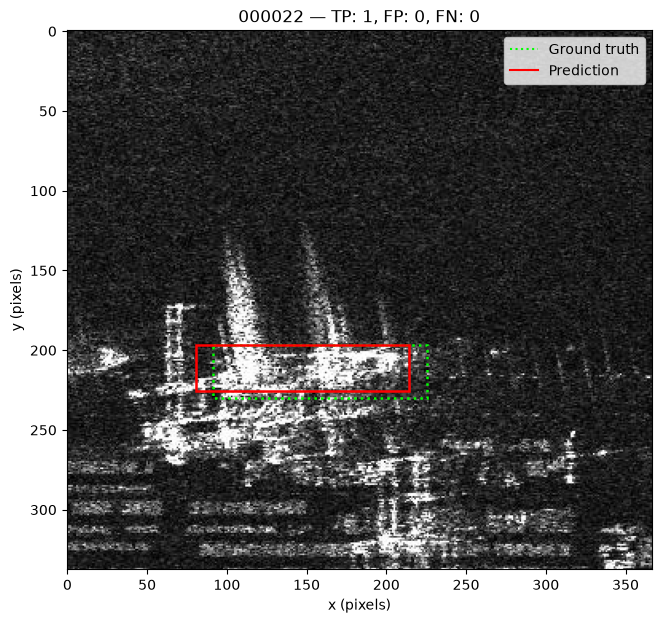

Evaluation Results:
   - id: 000032
   - path: SSDD_data/data/images/valid/000032.jpg
   - true_positives: 1
   - false_positives: 0
   - false_negatives: 1
   - precision: 1.0
   - recall: 0.5
   - f1: 0.6666666666666666
   - matches: [{'prediction_index': 0, 'label_index': 1, 'iou': 0.8374809608699324}]
   - false_positive_indices: []
   - false_negative_indices: [0]
   - iou_matrix: [[          0     0.83748]]


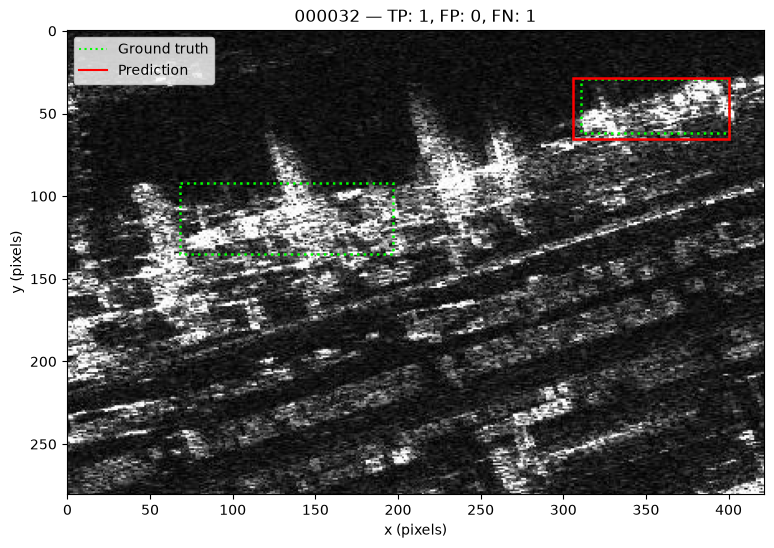

Evaluation Results:
   - id: 000036
   - path: SSDD_data/data/images/valid/000036.jpg
   - true_positives: 1
   - false_positives: 3
   - false_negatives: 0
   - precision: 0.25
   - recall: 1.0
   - f1: 0.4
   - matches: [{'prediction_index': 2, 'label_index': 0, 'iou': 0.8389744043035008}]
   - false_positive_indices: [0, 1, 3]
   - false_negative_indices: []
   - iou_matrix: [[    0.39908]
 [          0]
 [    0.83897]
 [    0.56872]]


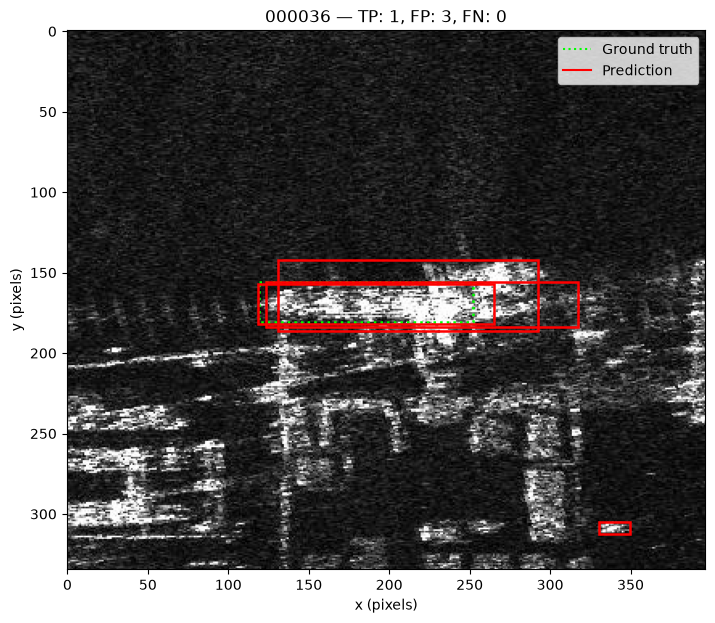

Evaluation Results:
   - id: 000043
   - path: SSDD_data/data/images/valid/000043.jpg
   - true_positives: 2
   - false_positives: 0
   - false_negatives: 0
   - precision: 1.0
   - recall: 1.0
   - f1: 1.0
   - matches: [{'prediction_index': 0, 'label_index': 0, 'iou': 0.7929339766973444}, {'prediction_index': 1, 'label_index': 1, 'iou': 0.7450741606640515}]
   - false_positive_indices: []
   - false_negative_indices: []
   - iou_matrix: [[    0.79293           0]
 [          0     0.74507]]


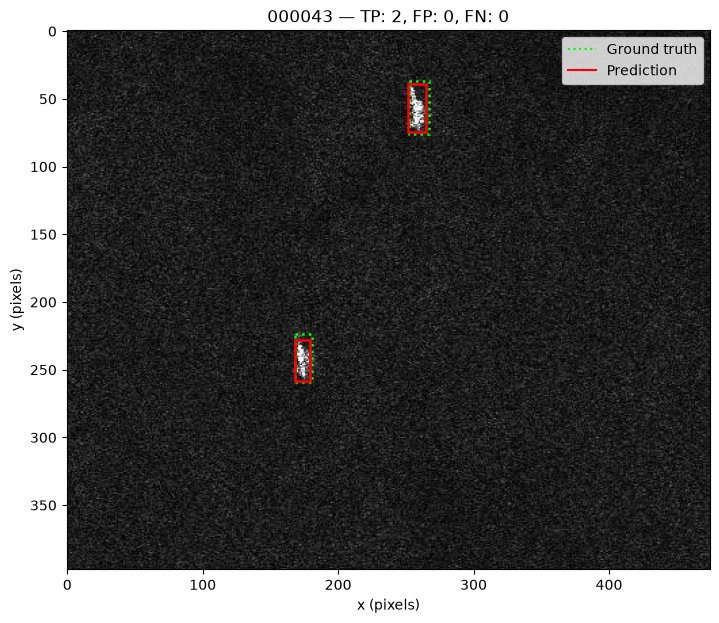

Evaluation Results:
   - id: 000046
   - path: SSDD_data/data/images/valid/000046.jpg
   - true_positives: 2
   - false_positives: 0
   - false_negatives: 0
   - precision: 1.0
   - recall: 1.0
   - f1: 1.0
   - matches: [{'prediction_index': 0, 'label_index': 0, 'iou': 0.8841095345493798}, {'prediction_index': 1, 'label_index': 1, 'iou': 0.6554348309260188}]
   - false_positive_indices: []
   - false_negative_indices: []
   - iou_matrix: [[    0.88411           0]
 [          0     0.65543]]


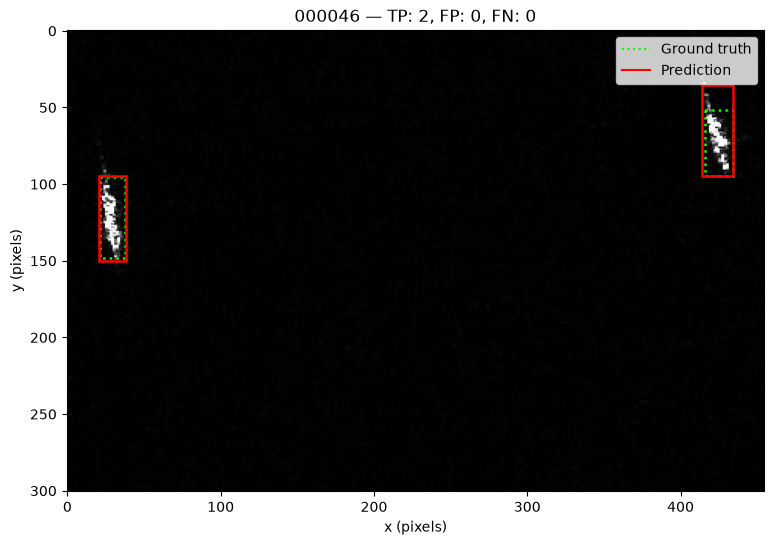

In [12]:
for img in val_images[:5]:
    pred = model.inference(img)
    sample = dl.load_sample(img)
    eval = sample.evaluate(pred['predicted_boxes'], iou_threshold= 0.3, plot=True)

Note that the Yolo model, like the deterministic model, most struggles to identify ships close to land, but performs much better at sea. This is because land surface contains many back scattering surfaces that confuse the model while the ocean surface provides a contrast that helps ships stand out.

## Model Comparison ##

After completing validation runs on both the deterministinc model and the deep learning model it is clear to see that the deep learning YOLO model out-performed the deterministic model in nevery evaluated category (below). 


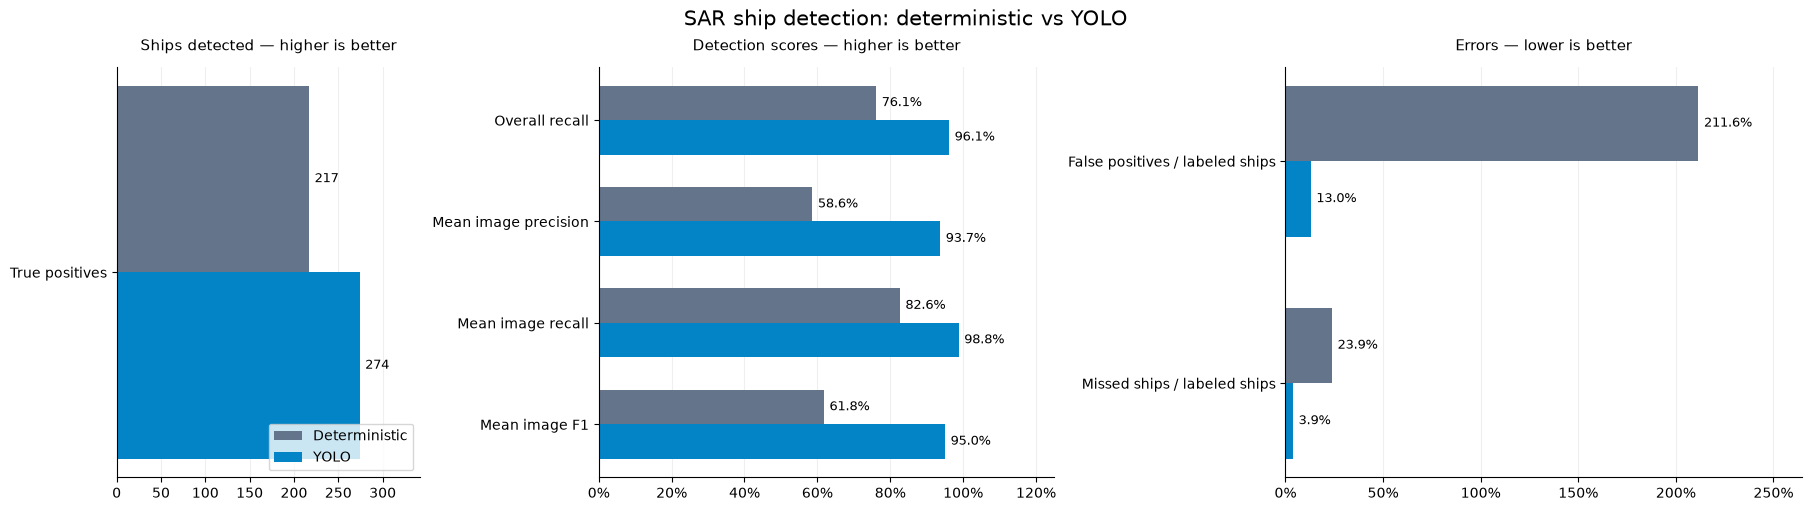

(<Figure size 1800x500 with 3 Axes>,
 array([<Axes: title={'center': 'Ships detected — higher is better'}>, <Axes: title={'center': 'Detection scores — higher is better'}>, <Axes: title={'center': 'Errors — lower is better'}>], dtype=object))

In [16]:
from helpers.model_comparison import plot_model_comparison
plot_model_comparison(det_results, yolo_results)

After analysis of both model's results, it is clear that the deterministic model was unable to account for one critical charictaristic that the YOLO model could account for: Shape. While the deterministic model did apply a filter to only consider masses of a certain size, that size only considered pixel count, not their shape. Additionally, the model only considered a binary evaluation (whether or not the pixels energy exceeded a certain threshold). In contrast, the YOLO model was able to learn the general shape that ships make. Additionally, it was able to identify things such as ship wakes or diminished pixels at the ships edge. All of this is evident by the high precision scores indicating tighter bounding boxes. 

Although the deep learning model out-performed the deterministic model, it is important to call-out that the deterministic model does perform to a considerable degree and offers a critical capability that the YOLO model does not: customization. While some level of customization is possible with the YOLO model through pre and post processing, the deterministic model offers the capacity for fine tuning to analyze specific types of data.

In summary, it is useful to understand the strengths and weaknesses of both model designs. Although the YOLO model won on all the considered benchmarks for this use case, it is important to select the correct tool for the correct use case. In either case, it is important to highlight that detection models are only one piece of a much larger detection pipeline and either of these models would only ever sit between layers of pre and post-processing that turn these analytics into practical information.